<a href="https://colab.research.google.com/github/elenamaggiore/Thesis_Elena_Maggiore/blob/datasets/DATASET_MBTI_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DATASET: MBTI dataset

This code will preprocess the PersonalityCafe Kaggle MBTI dataset, used as train set for the binary classification tasks related to MBTI dichotomies.

Libraries:

In [17]:
!pip -q install transformers

import ast, gc, hashlib, html, json, random, re, time
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             matthews_corrcoef, confusion_matrix)
from transformers import AutoTokenizer, AutoModelForCausalLM

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Loading dataset:

In [18]:
BASE = Path("/content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets")
MBTI_CSV = BASE / "mbti_1.csv"                       # Kaggle file (columns: type, posts)
OUT_DIR = BASE / "MBTI_train_set_output"
AUG_DIR = OUT_DIR / "llm_augmentation_ft"      # NEW folder: synthetic data from the fine-tuned GPT-2
FT_DIR = OUT_DIR / "gpt2_finetuned"                 # fine-tuned model checkpoint
for d in (OUT_DIR / "figures", OUT_DIR / "tables", AUG_DIR):
    d.mkdir(parents=True, exist_ok=True)

General parameters:

In [19]:
SEED = 11
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

MBTI_TYPES = ["ISTJ", "ISFJ", "INFJ", "INTJ", "ISTP", "ISFP", "INFP", "INTP",
              "ESTP", "ESFP", "ENFP", "ENTP", "ESTJ", "ESFJ", "ENFJ", "ENTJ"]

DIMS = {"introverted": ("I", "E"), "intuitive": ("N", "S"),
        "thinking": ("T", "F"), "perceiving": ("P", "J")} # First letter is 1, last letter is 0

URL_TOKEN = "URL"          # URL mention placeholder
MIN_POST_WORDS = 3
MIN_POSTS_PER_USER = 10

SPLIT = {"train": 0.70, "val": 0.30}
EXAMPLE_POSTS = 10         # consecutive posts per example

Device: cuda


Oversampling parameters (LLM model, embedding parameters):

In [20]:
GEN_MODEL = "gpt2"         # base model: it is FINE-TUNED on the training examples before generating
GEN_WINDOW_POSTS = 5       # posts of a real training example used as prompt (after the class-control code)
PROMPT_MAX_TOKENS = 150    # context window size
GEN_TEMP, GEN_TOP_K, GEN_TOP_P = 0.7, 50, 0.95
NUM_BEAMS = 1
NO_REPEAT_NGRAM = 2
GEN_LEN_RATIO, GEN_MIN_NEW, GEN_MAX_NEW = 0.75, 40, 100
MIN_SYN_WORDS = 10         # generated texts shorter than this are discarded
TARGET_BALANCE = 1.0       # fully balance the training examples of each dimension
MAX_SYN_PER_DIM = 12000    # compute cap on synthetic examples per dimension
GEN_BATCH_SIZE = 32
SAVE_EVERY = 1024          # checkpoint (and resume) granularity, in generated examples

# Fine-tuning (on the TRAIN examples only, label-masked text)
FT_MAX_TOKENS = 256        # max length of a fine-tuning sequence (control code + masked example)
FT_EPOCHS = 2
FT_LR = 5e-5
FT_BATCH_SIZE = 16
FT_WARMUP_FRAC = 0.05
FT_MAX_EXAMPLES = None     # e.g. 15000 to cap the training time; None = all training examples
FT_PPL_SAMPLE = 500        # validation examples used only to monitor perplexity (never for training)

Parameters of the classifier used for verification:

In [21]:
TFIDF_KW = dict(ngram_range=(1, 2), min_df=2, max_df=0.8, max_features=50000, sublinear_tf=True)
CLF_C = 1.0

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
_FIG_N = _TAB_N = 0

Label masking parameters:

In [22]:
MASKING = True

TYPE_TOKEN, FUNC_TOKEN = "TYPE_MENTION", "COGFUNC_MENTION"

RE_FUNC_NAME = re.compile(r"\b(?:introverted|extraverted|extroverted)\s+(?:intuition|sensing|sensation|thinking|feeling)\b", re.I)

RE_FUNC_STACK = re.compile(r"(?<![A-Za-z])[NSTF][ei](?:\s*[-/>+,]?\s*[NSTF][ei]){1,7}(?![A-Za-z])")

RE_FUNC_STACK_CI = re.compile(r"(?<![A-Za-z])(?:[nstf][ei]){3,4}(?![A-Za-z])", re.I)

RE_FUNC_SINGLE = re.compile(r"(?<![A-Za-z])[NSTF][ei](?![A-Za-z])"
                            r"(?:[-\s]?(?:dom(?:inant)?|aux(?:iliary)?|tert(?:iary)?|inf(?:erior)?|users?|driven|loop|grip)\b)?")

RE_TYPE = re.compile(r"(?<![A-Za-z])[EIX][NSX][TFX][JPX](?:'?s)?(?![A-Za-z])", re.I)

RE_URL = re.compile(r"(?:https?://|www\.)\S+", re.I)

Tokenizer with class-control codes:

In [23]:
CTRL = {t: f"<|{t.lower()}|>" for t in MBTI_TYPES}   # control code prepended to every fine-tuning / generation text

tok = AutoTokenizer.from_pretrained(GEN_MODEL)
tok.add_special_tokens({"additional_special_tokens": list(CTRL.values())})
tok.pad_token = tok.eos_token
tok.padding_side = "left"                            # left for generation (switched to right only while fine-tuning)

Functions:

In [24]:
# UTILITIES:
def savefig(name):
    global _FIG_N
    _FIG_N += 1
    plt.tight_layout()
    plt.savefig(OUT_DIR / "figures" / f"fig{_FIG_N:02d}_{name}.png", dpi=300, bbox_inches="tight")
    plt.show(); plt.close()

def savetab(df, name, index=True):
    global _TAB_N
    _TAB_N += 1
    df.to_csv(OUT_DIR / "tables" / f"tab{_TAB_N:02d}_{name}.csv", index=index, encoding="utf-8-sig")


# MASKING:
def _type_sub(m):
    letters = m.group(0)[:4].upper()
    return TYPE_TOKEN if letters.count("X") <= 1 else m.group(0)

def mask_text(t):
    # Returns (masked_text, n_type_mentions, n_function_mentions)
    n_f = 0
    for rx in (RE_FUNC_NAME, RE_FUNC_STACK, RE_FUNC_STACK_CI, RE_FUNC_SINGLE):
        t, k = rx.subn(FUNC_TOKEN, t); n_f += k
    n_t = 0
    def _count_sub(m):
        nonlocal n_t
        r = _type_sub(m)
        if r == TYPE_TOKEN: n_t += 1
        return r
    t = RE_TYPE.sub(_count_sub, t)
    return t, n_t, n_f

def mentions_own_type(t, own_type):
    return re.search(rf"(?<![A-Za-z]){own_type}(?:'?s)?(?![A-Za-z])", t, re.I) is not None

def clean_post(t):
    t = html.unescape(str(t))
    t = RE_URL.sub(f" {URL_TOKEN} ", t)
    return re.sub(r"\s+", " ", t).strip()

def dedup_key(t):
    return re.sub(r"[^a-z0-9]+", " ", t.lower()).strip()


# TRAIN/VALIDATION SPLIT:

def _safe_strat(s, min_n=3):
    # types with fewer than min_n users are pooled so that stratification never fails
    s = s.where(s.map(s.value_counts()) >= min_n, "RARE")
    return s if s.value_counts().min() >= 2 else None

def stratified_user_split(users, strat, fractions, seed):
    tr, rest = train_test_split(users, test_size=1 - fractions["train"], stratify=_safe_strat(strat), random_state=seed)
    va, te = train_test_split(rest, test_size=fractions["test"] / (fractions["val"] + fractions["test"]),
                              stratify=_safe_strat(strat.loc[rest.index]), random_state=seed)
    return tr, va, te

def make_examples(posts_df, k):
    out, ex_id = [], 0
    for uid, g in posts_df.sort_values(["user_id", "post_idx"]).groupby("user_id", sort=False):
        o, m = g["text_orig"].tolist(), g["text_masked"].tolist()
        starts = list(range(0, len(o), k))
        if len(starts) > 1 and len(o) - starts[-1] < max(1, k // 2):
            starts = starts[:-1]
        for j, s in enumerate(starts):
            e = starts[j + 1] if j + 1 < len(starts) else len(o)
            out.append((f"e{ex_id:06d}", uid, j, " ".join(o[s:e]), " ".join(m[s:e]), m[s:e]))
            ex_id += 1
    return pd.DataFrame(out, columns=["ex_id", "user_id", "ex_idx", "text_orig", "text_masked", "posts_masked"])


# BASELINE
def majority_baseline(y_train, y_eval):
    maj = int(y_train.mean() >= 0.5)
    pred = np.full(len(y_eval), maj)
    return dict(acc=accuracy_score(y_eval, pred), macro_f1=f1_score(y_eval, pred, average="macro", zero_division=0))


# OVERSAMPLING:
@torch.no_grad()
def generate_batch(prompts):
    enc = tok(prompts, return_tensors="pt", padding=True, truncation=True, max_length=PROMPT_MAX_TOKENS).to(DEVICE)
    n_in = enc["attention_mask"].sum(1).float().mean().item()
    max_new = int(np.clip(GEN_LEN_RATIO * n_in, GEN_MIN_NEW, GEN_MAX_NEW))
    out = gen_model.generate(**enc, do_sample=True, top_k=GEN_TOP_K, top_p=GEN_TOP_P, temperature=GEN_TEMP,
                             num_beams=NUM_BEAMS, no_repeat_ngram_size=NO_REPEAT_NGRAM, max_new_tokens=max_new,
                             pad_token_id=tok.eos_token_id)
    return tok.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)

def build_plan(dim, n_needed, minority_label, k_seed):
    # Deterministic list of (source_ex_id, source_user_id, source_type, prompt) -> allows resuming
    pool = tr_ex[tr_ex[dim] == minority_label].reset_index(drop=True)
    rng = random.Random(SEED + k_seed)
    plan = []
    for _ in range(n_needed):
        r = pool.iloc[rng.randrange(len(pool))]
        posts = r["posts_masked"]
        s = rng.randrange(0, max(1, len(posts) - GEN_WINDOW_POSTS + 1))
        prompt = f"{CTRL[r['type']]} " + " ".join(posts[s:s + GEN_WINDOW_POSTS])   # control code + real masked window
        plan.append((r["ex_id"], r["user_id"], r["type"], prompt))
    return plan

def generate_synthetic(dim, k_seed):
    n_needed = int(imb.loc[f"{DIMS[dim][0]}/{DIMS[dim][1]}", "needed_synthetic"])
    if n_needed <= 0:
        print(f"[{dim}] nothing to generate"); return
    minority_label = int(tr_ex[dim].mean() < 0.5)
    f_csv, f_prog = AUG_DIR / f"syn_{dim}.csv", AUG_DIR / f"syn_{dim}.progress.json"
    done = json.loads(f_prog.read_text())["done"] if f_prog.exists() else 0
    plan = build_plan(dim, n_needed, minority_label, k_seed)
    print(f"[{dim}] needed={n_needed:,} | already done={done:,} | minority label={minority_label}")
    t0 = time.time()
    for b0 in range(done, n_needed, SAVE_EVERY):
        block = plan[b0:b0 + SAVE_EVERY]
        order = sorted(range(len(block)), key=lambda i: len(block[i][3]))   # similar lengths per batch
        texts = [None] * len(block)
        for i in range(0, len(order), GEN_BATCH_SIZE):
            idx = order[i:i + GEN_BATCH_SIZE]
            for j, t in zip(idx, generate_batch([block[j][3] for j in idx])):
                texts[j] = t
        recs = []
        for (src_ex, src_user, src_type, _), t in zip(block, texts):
            masked, _, _ = mask_text(clean_post(t))
            if len(masked.split()) >= MIN_SYN_WORDS:
                recs.append(dict(syn_id=f"s_{dim}_{len(recs)}_{b0}", dim=dim, source_ex_id=src_ex,
                                 source_user_id=src_user, source_type=src_type, label=minority_label, text_masked=masked))
        pd.DataFrame(recs).to_csv(f_csv, mode="a", header=not f_csv.exists(), index=False)
        f_prog.write_text(json.dumps({"done": b0 + len(block)}))
        el = time.time() - t0
        print(f"  {b0 + len(block):,}/{n_needed:,} | kept {len(recs)}/{len(block)} | {el/60:.1f} min elapsed")
    gc.collect(); torch.cuda.empty_cache()


# FINE-TUNING:
def _encode_train(texts):
    tok.padding_side = "right"                       # right padding for training
    enc = tok(texts, return_tensors="pt", padding=True, truncation=True, max_length=FT_MAX_TOKENS)
    tok.padding_side = "left"
    labels = enc["input_ids"].clone()
    labels[enc["attention_mask"] == 0] = -100        # padding is ignored by the loss (the real EOS is kept)
    enc["labels"] = labels
    return {k: v.to(DEVICE) for k, v in enc.items()}

@torch.no_grad()
def perplexity(model, texts, bs=32):
    model.eval()
    tot_loss, tot_tok = 0.0, 0
    for i in range(0, len(texts), bs):
        enc = _encode_train(texts[i:i + bs])
        n = int((enc["labels"][:, 1:] != -100).sum())
        tot_loss += model(**enc).loss.item() * n
        tot_tok += n
    return float(np.exp(tot_loss / tot_tok))

def finetune_gpt2(train_texts, val_texts):
    model = AutoModelForCausalLM.from_pretrained(GEN_MODEL)
    model.resize_token_embeddings(len(tok))          # make room for the 16 control codes
    model.to(DEVICE)
    print(f"Validation perplexity BEFORE fine-tuning: {perplexity(model, val_texts):.1f}")
    model.train()
    opt = torch.optim.AdamW(model.parameters(), lr=FT_LR, weight_decay=0.01)
    n_steps = FT_EPOCHS * int(np.ceil(len(train_texts) / FT_BATCH_SIZE))
    sched = get_linear_schedule_with_warmup(opt, int(FT_WARMUP_FRAC * n_steps), n_steps)
    use_amp = DEVICE == "cuda"
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    rng = np.random.default_rng(SEED)
    step, run, t0 = 0, 0.0, time.time()
    for ep in range(FT_EPOCHS):
        order = rng.permutation(len(train_texts))
        for i in range(0, len(order), FT_BATCH_SIZE):
            enc = _encode_train([train_texts[j] for j in order[i:i + FT_BATCH_SIZE]])
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                loss = model(**enc).loss
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            opt.zero_grad(set_to_none=True); sched.step()
            step += 1; run += loss.item()
            if step % 250 == 0:
                print(f"  epoch {ep + 1}/{FT_EPOCHS} | step {step}/{n_steps} | loss {run / 250:.3f} | {(time.time() - t0) / 60:.1f} min")
                run = 0.0
        print(f"Validation perplexity after epoch {ep + 1}: {perplexity(model, val_texts):.1f}")
        model.train()
    del opt, sched, scaler
    gc.collect(); torch.cuda.empty_cache()
    return model.eval()


# EVALUATION:
def metrics(y, pred):
    return dict(n=len(y), acc=accuracy_score(y, pred), bal_acc=balanced_accuracy_score(y, pred),
                macro_f1=f1_score(y, pred, average="macro", zero_division=0),
                mcc=matthews_corrcoef(y, pred),
                f1_pos=f1_score(y, pred, pos_label=1, zero_division=0),
                f1_neg=f1_score(y, pred, pos_label=0, zero_division=0))

def user_level(split_df, p, col):
    t = pd.DataFrame({"user_id": split_df["user_id"].values, "p": p, "y": split_df[col].values})
    t = t.groupby("user_id").agg(p=("p", "mean"), y=("y", "first"))
    return t["y"].values, (t["p"].values >= 0.5).astype(int)

## STEP ZERO: assessing the dataset

In [25]:
raw = pd.read_csv(MBTI_CSV)
raw.columns = [c.strip().lower() for c in raw.columns]
assert {"type", "posts"} <= set(raw.columns), f"Unexpected columns: {list(raw.columns)}"
raw.insert(0, "user_id", [f"u{i:05d}" for i in range(len(raw))])
print(f"Rows in the raw file: {len(raw):,}")

Rows in the raw file: 8,675


## STEP ONE: validating labels

In [26]:
raw["type"] = raw["type"].astype("string").str.strip().str.upper()
invalid = ~raw["type"].isin(MBTI_TYPES)
no_posts = raw["posts"].isna() | (raw["posts"].astype(str).str.strip() == "")
dup_rows = raw.duplicated(subset=["type", "posts"], keep="first")
print(f"Malformed or missing type: {invalid.sum()} | empty posts: {no_posts.sum()} | fully duplicated rows: {dup_rows.sum()}")
df = raw[~invalid & ~no_posts & ~dup_rows].copy().reset_index(drop=True)

Malformed or missing type: 0 | empty posts: 0 | fully duplicated rows: 0


## STEP TWO: creating binary tasks

In [27]:
for i, (col, (p1, p0)) in enumerate(DIMS.items()):
    df[col] = (df["type"].str[i] == p1).astype(int)
rebuilt = df.apply(lambda r: "".join(DIMS[c][0] if r[c] == 1 else DIMS[c][1] for c in DIMS), axis=1)
assert (rebuilt == df["type"]).all(), "Type reconstruction failed"
print(f"Valid users: {len(df):,}")
savetab(pd.DataFrame({"column": list(DIMS), "coded_1": [v[0] for v in DIMS.values()],
                      "coded_0": [v[1] for v in DIMS.values()]}), "target_encoding", index=False)
display(df[["user_id", "type"] + list(DIMS)].head())

Valid users: 8,675


,user_id,type,introverted,intuitive,thinking,perceiving
0,u00000,INFJ,1,1,0,0
1,u00001,ENTP,0,1,1,1
2,u00002,INTP,1,1,1,1
3,u00003,INTJ,1,1,1,0
4,u00004,ENTJ,0,1,1,0


## STEP THREE: label masking

In [28]:
audit = Counter()
rows = []
for uid, typ, posts in zip(df["user_id"], df["type"], df["posts"]):
    s = str(posts).strip().strip("'").strip('"')
    parts = s.split("|||")
    audit["posts_raw"] += len(parts)
    seen, k = set(), 0
    for p in parts:
        c = clean_post(p)
        if not c:
            audit["empty_posts"] += 1; continue
        if len(c.split()) < MIN_POST_WORDS:
            audit["short_posts"] += 1; continue
        key = dedup_key(c)
        if key in seen:
            audit["duplicate_posts_within_user"] += 1; continue
        seen.add(key)
        rows.append((uid, k, c, key)); k += 1
posts_df = pd.DataFrame(rows, columns=["user_id", "post_idx", "text_orig", "key"])
audit["posts_kept"] = len(posts_df)

# posts shared across users (reported, not removed)
kc = posts_df.groupby("key")["user_id"].nunique()
audit["posts_shared_across_users"] = int(posts_df["key"].map(kc).gt(1).sum())
posts_df = posts_df.drop(columns="key")

# users with too few usable posts
cnt = posts_df.groupby("user_id").size()
keep_users = cnt[cnt >= MIN_POSTS_PER_USER].index
audit["users_dropped_few_posts"] = int(len(df) - len(keep_users))
posts_df = posts_df[posts_df["user_id"].isin(keep_users)].reset_index(drop=True)
df = df[df["user_id"].isin(keep_users)].reset_index(drop=True)
audit["users_final"], audit["posts_final"] = len(df), len(posts_df)
audit_df = pd.Series(audit, name="count").to_frame()
display(audit_df); savetab(audit_df, "cleaning_audit")

# masking (original and masked conditions)
own = dict(zip(df["user_id"], df["type"]))
m = [mask_text(t) for t in posts_df["text_orig"]]
posts_df["text_masked"] = [x[0] for x in m]
posts_df["n_type_mentions"] = [x[1] for x in m]
posts_df["n_func_mentions"] = [x[2] for x in m]
posts_df["own_type_mention"] = [mentions_own_type(t, own[u]) for t, u in zip(posts_df["text_orig"], posts_df["user_id"])]
del m; gc.collect()
print(f"Posts with a type mention: {(posts_df.n_type_mentions > 0).mean():.2%} | "
      f"with a function mention: {(posts_df.n_func_mentions > 0).mean():.2%}")

# validation:
u = posts_df.groupby("user_id").agg(n_posts=("post_idx", "size"), type_m=("n_type_mentions", "sum"),
                                    func_m=("n_func_mentions", "sum"), own_m=("own_type_mention", "sum"))
u = u.join(df.set_index("user_id")["type"])
leak = u.groupby("type").agg(users=("n_posts", "size"),
                             pct_users_type_mention=("type_m", lambda s: (s > 0).mean() * 100),
                             pct_users_func_mention=("func_m", lambda s: (s > 0).mean() * 100),
                             pct_users_own_type_mention=("own_m", lambda s: (s > 0).mean() * 100)).round(1)
leak.loc["ALL"] = [len(u), (u.type_m > 0).mean() * 100, (u.func_m > 0).mean() * 100, (u.own_m > 0).mean() * 100]
leak = leak.round(1); display(leak); savetab(leak, "label_leakage_before_masking")

# residual scan on the masked text
RESIDUAL = {
    "type-like token": re.compile(r"(?<![A-Za-z])[EI][NS][TF][JP](?![A-Za-z])", re.I),
    "function + role": re.compile(r"(?<![A-Za-z])[nstf][ei][-\s](?:dom|aux|tert|inf)\w*", re.I),
    "'cognitive function'": re.compile(r"cognitive functions?", re.I),
    "'socionics' / 'enneagram'": re.compile(r"socionics|enneagram", re.I),
}
res = {k: int(posts_df["text_masked"].str.contains(rx).sum()) for k, rx in RESIDUAL.items()}
display(pd.Series(res, name="posts with residual pattern").to_frame())

# manual audit sample
s = posts_df[(posts_df.n_type_mentions + posts_df.n_func_mentions) > 0].sample(15, random_state=SEED)
for _, r in s.iterrows():
    print("ORIG  :", r.text_orig[:220]); print("MASKED:", r.text_masked[:220]); print("-" * 80)

,count
posts_raw,422845
short_posts,23731
duplicate_posts_within_user,1470
empty_posts,1088
posts_kept,396556
posts_shared_across_users,2169
users_dropped_few_posts,26
users_final,8649
posts_final,396394


Posts with a type mention: 20.18% | with a function mention: 3.87%


,users,pct_users_type_mention,pct_users_func_mention,pct_users_own_type_mention
type,,,,
ENFJ,190.0,97.4,49.5,90.0
ENFP,672.0,97.9,46.1,92.6
ENTJ,231.0,99.1,52.8,89.2
ENTP,684.0,97.2,60.4,91.8
ESFJ,42.0,97.6,59.5,83.3
ESFP,48.0,93.8,50.0,77.1
ESTJ,39.0,92.3,28.2,74.4
ESTP,89.0,98.9,58.4,92.1
INFJ,1466.0,95.8,51.2,89.2


,posts with residual pattern
type-like token,0
function + role,29
'cognitive function',1293
'socionics' / 'enneagram',2876


ORIG  : YAY A FELLOW INFP ACE!! :tongue: do you like hugs? cos I think this calls for hugs... and cake! BTW I spoke to a load of other aces on AVEN yesterday and it seems that a lot of them are NF's :3...
MASKED: YAY A FELLOW TYPE_MENTION ACE!! :tongue: do you like hugs? cos I think this calls for hugs... and cake! BTW I spoke to a load of other aces on AVEN yesterday and it seems that a lot of them are NF's :3...
--------------------------------------------------------------------------------
ORIG  : Speak of Necromancy and be freaked out with knowledge of the actual Black Arts. Otherwise it is a storm in a tea cup. Fair point? INTJs are allowing personality profile category determine what...
MASKED: Speak of Necromancy and be freaked out with knowledge of the actual Black Arts. Otherwise it is a storm in a tea cup. Fair point? TYPE_MENTION are allowing personality profile category determine what...
--------------------------------------------------------------------------------
ORIG 

## STEP FOUR: descriptive statistics

,mean,sd,median
posts per user,45.83,6.18,48.00
words per user,1270.17,310.91,1321.00
words per post (all posts),27.71,11.83,33.00
words per post (user means),27.48,4.87,28.12


,pole_1,pole_0,n_1,n_0,pct_1,pct_0,majority_pole,majority_baseline_acc
dimension,,,,,,,,
I/E,I,E,6654,1995,76.934,23.066,I,0.769
N/S,N,S,7458,1191,86.230,13.770,N,0.862
T/F,T,F,3967,4682,45.867,54.133,F,0.541
P/J,P,J,5225,3424,60.412,39.588,P,0.604


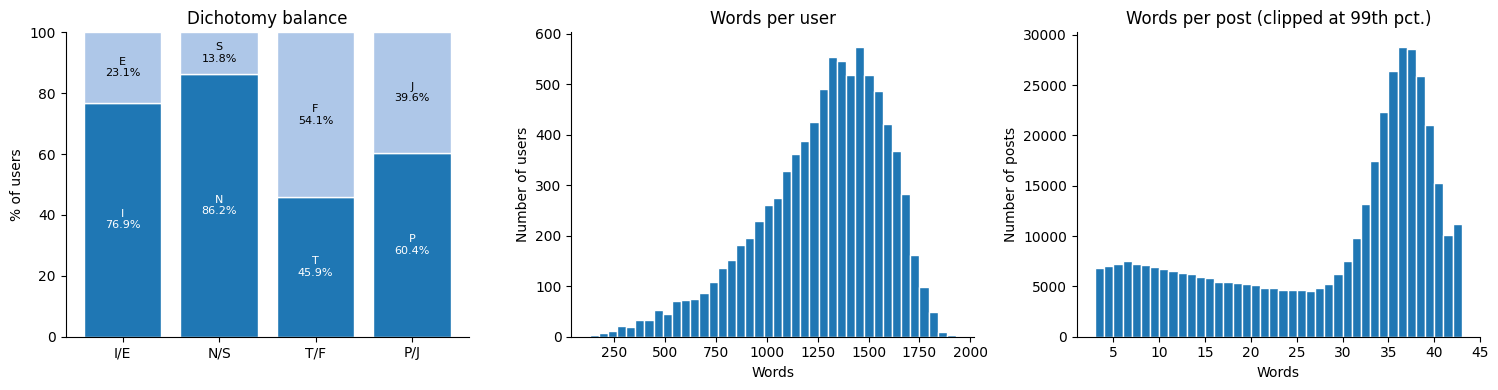

In [29]:
posts_df["n_words"] = posts_df["text_orig"].str.split().str.len()
ud = posts_df.groupby("user_id").agg(n_posts=("post_idx", "size"), words_user=("n_words", "sum"),
                                     words_post_mean=("n_words", "mean"))
stats = pd.DataFrame({
    "mean": [ud.n_posts.mean(), ud.words_user.mean(), posts_df.n_words.mean(), ud.words_post_mean.mean()],
    "sd":   [ud.n_posts.std(), ud.words_user.std(), posts_df.n_words.std(), ud.words_post_mean.std()],
    "median": [ud.n_posts.median(), ud.words_user.median(), posts_df.n_words.median(), ud.words_post_mean.median()],
}, index=["posts per user", "words per user", "words per post (all posts)", "words per post (user means)"]).round(2)
display(stats); savetab(stats, "length_statistics")

# Class balance of the four dichotomies: one row per dimension, identical columns for all of them
rows = []
for col, (p1, p0) in DIMS.items():
    n1 = int(df[col].sum())
    n0 = len(df) - n1
    rows.append({"dimension": f"{p1}/{p0}", "pole_1": p1, "pole_0": p0,
                 "n_1": n1, "n_0": n0,
                 "pct_1": n1 / len(df) * 100, "pct_0": n0 / len(df) * 100,
                 "majority_pole": p1 if n1 >= n0 else p0,
                 "majority_baseline_acc": max(n1, n0) / len(df)})
bal = pd.DataFrame(rows).set_index("dimension")
display(bal.round(3)); savetab(bal.round(4), "dichotomy_balance")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Dichotomy balance (% of users), stacked: pole coded 1 at the bottom, pole coded 0 on top
x = np.arange(len(bal))
b1 = axes[0].bar(x, bal["pct_1"], edgecolor="white", color="#1f77b4")
b0 = axes[0].bar(x, bal["pct_0"], bottom=bal["pct_1"], edgecolor="white", color="#aec7e8")
for i, (dim, r) in enumerate(bal.iterrows()):
    axes[0].text(i, r["pct_1"] / 2, f"{r['pole_1']}\n{r['pct_1']:.1f}%", ha="center", va="center", fontsize=8, color="white")
    axes[0].text(i, r["pct_1"] + r["pct_0"] / 2, f"{r['pole_0']}\n{r['pct_0']:.1f}%", ha="center", va="center", fontsize=8)
axes[0].set_xticks(x, bal.index)
axes[0].set(title="Dichotomy balance", ylabel="% of users", ylim=(0, 100))

axes[1].hist(ud.words_user, bins=40, edgecolor="white")
axes[1].set(title="Words per user", xlabel="Words", ylabel="Number of users")

axes[2].hist(posts_df.n_words.clip(upper=posts_df.n_words.quantile(0.99)), bins=40, edgecolor="white")
axes[2].set(title="Words per post (clipped at 99th pct.)", xlabel="Words", ylabel="Number of posts")
savefig("dichotomy_and_length_distributions")

## STEP FIVE: train/validation split

In [30]:
def _safe_strat(s, min_n=3):
    # types with fewer than min_n users are pooled so that stratification never fails
    s = s.where(s.map(s.value_counts()) >= min_n, "RARE")
    return s if s.value_counts().min() >= 2 else None

def stratified_user_split(users, strat, fractions, seed):
    # two-way split by user, stratified on the 16 types
    val_size = fractions["val"] / (fractions["train"] + fractions["val"])
    return train_test_split(users, test_size=val_size, stratify=_safe_strat(strat), random_state=seed)

def make_examples(posts_df, k):
    out, ex_id = [], 0
    for uid, g in posts_df.sort_values(["user_id", "post_idx"]).groupby("user_id", sort=False):
        o, m = g["text_orig"].tolist(), g["text_masked"].tolist()
        starts = list(range(0, len(o), k))
        if len(starts) > 1 and len(o) - starts[-1] < max(1, k // 2):
            starts = starts[:-1]
        for j, s in enumerate(starts):
            e = starts[j + 1] if j + 1 < len(starts) else len(o)
            out.append((f"e{ex_id:06d}", uid, j, " ".join(o[s:e]), " ".join(m[s:e]), m[s:e]))
            ex_id += 1
    return pd.DataFrame(out, columns=["ex_id", "user_id", "ex_idx", "text_orig", "text_masked", "posts_masked"])

# Split by user BEFORE building examples
users = df.set_index("user_id")["type"]
tr, va = stratified_user_split(users, users, SPLIT, SEED)
assert not (set(tr.index) & set(va.index)), "Users shared between train and validation!"
split_of = {**{u: "train" for u in tr.index}, **{u: "val" for u in va.index}}
assert len(split_of) == len(df)
df["split"] = df["user_id"].map(split_of)
print(df["split"].value_counts().to_string())
savetab(df[["user_id", "type", "split"]], "user_split_assignment", index=False)

ex = make_examples(posts_df, EXAMPLE_POSTS)
ex = ex.merge(df[["user_id", "type", "split"] + list(DIMS)], on="user_id", how="left")
print(f"Examples: {len(ex):,} ({EXAMPLE_POSTS} posts each)")
display(ex.groupby("split").agg(users=("user_id", "nunique"), examples=("ex_id", "size")))

split
train    6054
val      2595
Examples: 40,605 (10 posts each)


,users,examples
split,,
train,6054,28429
val,2595,12176


## STEP SIX: BASELINE

In [31]:
tr_ex = ex[ex.split == "train"]
imb = []
for col, (p1, p0) in DIMS.items():
    n1, n0 = int(tr_ex[col].sum()), int((1 - tr_ex[col]).sum())
    imb.append(dict(dimension=f"{p1}/{p0}", train_examples_1=n1, train_examples_0=n0,
                    minority=p1 if n1 < n0 else p0, deficit=abs(n1 - n0),
                    needed_synthetic=min(MAX_SYN_PER_DIM, int(abs(n1 - n0) * TARGET_BALANCE))))
imb = pd.DataFrame(imb).set_index("dimension"); display(imb); savetab(imb, "imbalance_and_synthetic_budget")

,train_examples_1,train_examples_0,minority,deficit,needed_synthetic
dimension,,,,,
I/E,21823,6606,E,15217,12000
N/S,24574,3855,S,20719,12000
T/F,13037,15392,T,2355,2355
P/J,17179,11250,J,5929,5929


## STEP SEVEN: OVERSAMPLING WITH FINE-TUNING

Fine-Tunning GPT-2 on the train set:

In [32]:
from transformers import get_linear_schedule_with_warmup

assert set(tr_ex["user_id"]) <= set(tr.index), "Fine-tuning data must come from training users only!"

if (FT_DIR / "config.json").exists():
    print("Loading the fine-tuned model from", FT_DIR)
    gen_model = AutoModelForCausalLM.from_pretrained(FT_DIR)
else:
    ft_src = tr_ex if FT_MAX_EXAMPLES is None else tr_ex.sample(min(FT_MAX_EXAMPLES, len(tr_ex)), random_state=SEED)
    ft_texts = [f"{CTRL[t]} {x}{tok.eos_token}" for t, x in zip(ft_src["type"], ft_src["text_masked"])]
    val_src = ex[ex.split == "val"].sample(min(FT_PPL_SAMPLE, int((ex.split == "val").sum())), random_state=SEED)
    val_texts = [f"{CTRL[t]} {x}{tok.eos_token}" for t, x in zip(val_src["type"], val_src["text_masked"])]
    print(f"Fine-tuning on {len(ft_texts):,} training examples ({FT_EPOCHS} epochs)")
    gen_model = finetune_gpt2(ft_texts, val_texts)
    gen_model.save_pretrained(FT_DIR); tok.save_pretrained(FT_DIR)

if DEVICE == "cuda":
    gen_model = gen_model.half()
gen_model = gen_model.to(DEVICE).eval()
gc.collect(); torch.cuda.empty_cache()

# qualitative check: texts generated from the control code alone
for t in ("ENFP", "ISTJ"):
    print(f"[{t}]")
    for g in generate_batch([CTRL[t]] * 3):
        print("  -", g.strip()[:250])

Fine-tuning on 28,429 training examples (2 epochs)


model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

...

Validation perplexity BEFORE fine-tuning: 55.8


/tmp/ipykernel_1526/629140512.py:166: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/tmp/ipykernel_1526/629140512.py:179: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  opt.zero_grad(set_to_none=True); sched.step()


  epoch 1/2 | step 250/3554 | loss 3.911 | 1.8 min
  epoch 1/2 | step 500/3554 | loss 3.751 | 3.6 min
  epoch 1/2 | step 750/3554 | loss 3.715 | 5.5 min
  epoch 1/2 | step 1000/3554 | loss 3.691 | 7.3 min
  epoch 1/2 | step 1250/3554 | loss 3.683 | 9.2 min
  epoch 1/2 | step 1500/3554 | loss 3.681 | 11.1 min
  epoch 1/2 | step 1750/3554 | loss 3.660 | 13.0 min
Validation perplexity after epoch 1: 35.5
  epoch 2/2 | step 2000/3554 | loss 3.598 | 15.0 min
  epoch 2/2 | step 2250/3554 | loss 3.598 | 16.9 min
  epoch 2/2 | step 2500/3554 | loss 3.591 | 18.7 min
  epoch 2/2 | step 2750/3554 | loss 3.596 | 20.6 min
  epoch 2/2 | step 3000/3554 | loss 3.581 | 22.5 min
  epoch 2/2 | step 3250/3554 | loss 3.579 | 24.4 min
  epoch 2/2 | step 3500/3554 | loss 3.589 | 26.2 min
Validation perplexity after epoch 2: 34.9


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[ENFP]
  - I know what you mean, but I just wanted to say, I'm pretty sure I don't really want to be in a relationship. I have a crush on someone I barely know, and it
  - I've been wanting to know what that means. I'm going to post a picture of me right now and I'll get a response from you soon. :P I know I shouldn't be,
  - If you're interested, here's a quick explanation: URL URL *hugs* *likes* URL This is me. I'm not sure what you mean by 'cute' and '
[ISTJ]
  - I've had a couple of different TYPE_MENTION friends that I can't speak for, but I'm actually quite sure that they are just very loyal. I think it's more because they care
  - I am TYPE_MENTION. I love talking about stuff and talking to people. It's very fulfilling and I find it comforting. My friends are often nice and helpful but I don't know them
  - I love being able to relate to people, and I would like to get a better understanding of myself and what I see in people. I like being a bit more open about myself in... I ha

In [33]:
# one pass per dimension (each call can be interrupted and re-run)
for k, dim in enumerate(DIMS):
    generate_synthetic(dim, k)

# sanity checks: synthetic data only derive from training users
syn = {}
for dim in DIMS:
    f = AUG_DIR / f"syn_{dim}.csv"
    if f.exists():
        syn[dim] = pd.read_csv(f)
        assert set(syn[dim]["source_user_id"]) <= set(tr.index), "Synthetic data from a non-training user!"
print({d: len(s) for d, s in syn.items()})
display(syn["introverted"].sample(3, random_state=SEED)[["label", "text_masked"]] if "introverted" in syn else "no synthetic data")

[introverted] needed=12,000 | already done=0 | minority label=0
  1,024/12,000 | kept 1015/1024 | 0.8 min elapsed
  2,048/12,000 | kept 1018/1024 | 1.5 min elapsed
  3,072/12,000 | kept 1016/1024 | 2.2 min elapsed
  4,096/12,000 | kept 1018/1024 | 2.9 min elapsed
  5,120/12,000 | kept 1018/1024 | 3.6 min elapsed
  6,144/12,000 | kept 1017/1024 | 4.4 min elapsed
  7,168/12,000 | kept 1015/1024 | 5.1 min elapsed
  8,192/12,000 | kept 1014/1024 | 5.8 min elapsed
  9,216/12,000 | kept 1020/1024 | 6.5 min elapsed
  10,240/12,000 | kept 1019/1024 | 7.2 min elapsed
  11,264/12,000 | kept 1016/1024 | 7.9 min elapsed
  12,000/12,000 | kept 731/736 | 8.4 min elapsed
[intuitive] needed=12,000 | already done=0 | minority label=0
  1,024/12,000 | kept 1016/1024 | 0.7 min elapsed
  2,048/12,000 | kept 1016/1024 | 1.4 min elapsed
  3,072/12,000 | kept 1012/1024 | 2.1 min elapsed
  4,096/12,000 | kept 1018/1024 | 2.8 min elapsed
  5,120/12,000 | kept 1016/1024 | 3.5 min elapsed
  6,144/12,000 | kept 1

,label,text_masked
1669,0,him out of the house. Now I can't think of any...
10485,0,will... I love my TYPE/TYPE_FJ friends. They'r...
4175,0,It just seems like you are... I agree that COG...


Memorisation check:

In [34]:
def shingles(text, n=8):
    w = text.lower().split()
    return {hash(" ".join(w[i:i + n])) for i in range(max(0, len(w) - n + 1))}

train_sh = set()
for t in tr_ex["text_masked"].sample(min(len(tr_ex), 5000), random_state=SEED):
    train_sh |= shingles(t)

mem_rows = []
for dim, s in syn.items():
    smp = s.sample(min(len(s), 1000), random_state=SEED)
    ov = []
    for t in smp["text_masked"]:
        sh = shingles(t)
        ov.append(len(sh & train_sh) / len(sh) if sh else 0.0)
    ov = np.array(ov)
    mem_rows.append(dict(dimension=f"{DIMS[dim][0]}/{DIMS[dim][1]}", n_synthetic=len(s),
                         pct_exact_duplicates=s["text_masked"].duplicated().mean() * 100,
                         mean_shingle_overlap=ov.mean(), pct_texts_overlap_gt_50=(ov > 0.5).mean() * 100))
mem = pd.DataFrame(mem_rows).set_index("dimension").round(3)
display(mem); savetab(mem, "synthetic_memorisation_check")
del train_sh; gc.collect()

,n_synthetic,pct_exact_duplicates,mean_shingle_overlap,pct_texts_overlap_gt_50
dimension,,,,
I/E,11917,0.0,0.000,0.0
N/S,11901,0.0,0.001,0.0
T/F,2328,0.0,0.001,0.0
P/J,5894,0.0,0.001,0.0


0

## STEP EIGHT: ROBUSTNESS EVALUATION

done: original    I/E
done: masked      I/E
done: masked+LLM  I/E
done: original    N/S
done: masked      N/S
done: masked+LLM  N/S
done: original    T/F
done: masked      T/F
done: masked+LLM  T/F
done: original    P/J
done: masked      P/J
done: masked+LLM  P/J


condition,masked,masked+LLM,original
dimension,,,
I/E,0.438,0.472,0.540
N/S,0.465,0.471,0.465
P/J,0.500,0.548,0.688
T/F,0.797,0.787,0.855
mean,0.550,0.569,0.637


Majority-class macro-F1 on test (example level):
 dimension
I/E    0.428
N/S    0.465
T/F    0.350
P/J    0.376


,macro-F1 gap (original - masked)
dimension,
I/E,0.102
N/S,0.000
P/J,0.188
T/F,0.057
mean,0.087


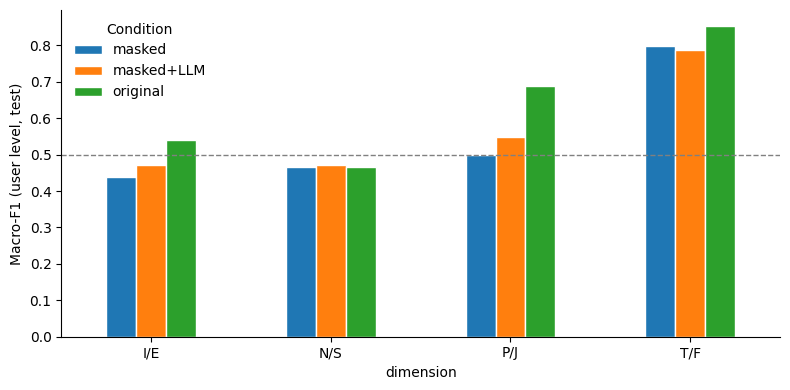

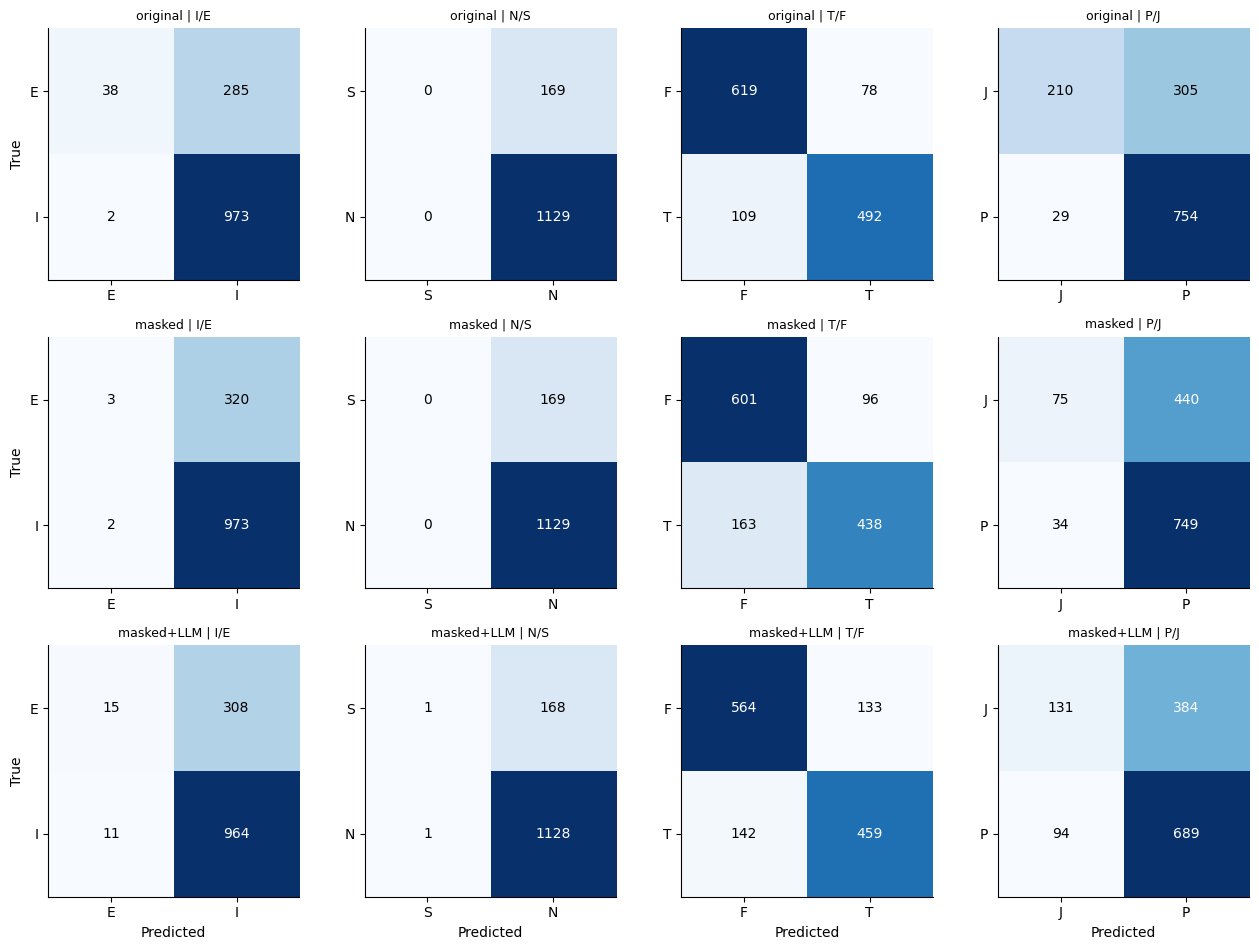

In [35]:
CONDITIONS = [("original", "text_orig", False), ("masked", "text_masked", False), ("masked+LLM", "text_masked", True)]
val_ex, test_ex = ex[ex.split == "val"], ex[ex.split == "test"]

# Fix: If test split is empty, split the validation set into 50/50 val and test sets
if len(test_ex) == 0 and len(val_ex) > 0:
    unique_val_users = val_ex["user_id"].unique()
    np.random.seed(SEED)
    val_users, test_users = train_test_split(unique_val_users, test_size=0.5, random_state=SEED)
    test_ex = val_ex[val_ex["user_id"].isin(test_users)].copy()
    val_ex = val_ex[val_ex["user_id"].isin(val_users)].copy()
    # Update split column for correct grouping
    val_ex["split"] = "val"
    test_ex["split"] = "test"

results, cms, vec_cache = [], {}, {}

for col, (p1, p0) in DIMS.items():
    dname = f"{p1}/{p0}"
    for split_name, sdf in (("val", val_ex), ("test", test_ex)):
        if len(sdf) == 0: continue
        mb = majority_baseline(tr_ex[col], sdf[col])
        results.append(dict(condition="majority", dimension=dname, split=split_name, level="example", **mb))
    for cond, tcol, use_aug in CONDITIONS:
        if use_aug and col not in syn:
            continue
        X_text = tr_ex[tcol].tolist(); y = tr_ex[col].values
        if use_aug:
            X_text = X_text + syn[col]["text_masked"].tolist(); y = np.concatenate([y, syn[col]["label"].values])
        if use_aug or cond not in vec_cache:
            vec = TfidfVectorizer(**TFIDF_KW); Xtr = vec.fit_transform(X_text)
            if not use_aug: vec_cache[cond] = (vec, Xtr)
        else:
            vec, Xtr = vec_cache[cond]
        clf = LogisticRegression(C=CLF_C, max_iter=2000, solver="liblinear", random_state=SEED).fit(Xtr, y)
        for split_name, sdf in (("val", val_ex), ("test", test_ex)):
            if len(sdf) == 0: continue
            p = clf.predict_proba(vec.transform(sdf[tcol]))[:, 1]
            results.append(dict(condition=cond, dimension=dname, split=split_name, level="example",
                                train_size=len(y), **metrics(sdf[col].values, (p >= 0.5).astype(int))))
            yu, pu = user_level(sdf, p, col)
            results.append(dict(condition=cond, dimension=dname, split=split_name, level="user",
                                train_size=len(y), **metrics(yu, pu)))
            if split_name == "test":
                cms[(cond, dname)] = confusion_matrix(yu, pu, labels=[0, 1])
        print(f"done: {cond:11s} {dname}")
    gc.collect()

res = pd.DataFrame(results)
res["pos_pole"] = res["dimension"].str[0]; res["neg_pole"] = res["dimension"].str[2]
savetab(res.round(4), "evaluation_results", index=False)

# summary: macro-F1 on the user-level test set
summ = res[(res.split == "test") & (res.level == "user")].pivot(index="dimension", columns="condition", values="macro_f1")
summ.loc["mean"] = summ.mean()
display(summ.round(3)); savetab(summ.round(4), "summary_test_macroF1_user_level")

base = res[(res.condition == "majority") & (res.split == "test")].set_index("dimension")["macro_f1"]
print("Majority-class macro-F1 on test (example level):\n", base.round(3).to_string())

if {"original", "masked"} <= set(summ.columns):
    gap = (summ["original"] - summ["masked"]).rename("macro-F1 gap (original - masked)")
    display(gap.round(3).to_frame())

summ.drop(index="mean").plot(kind="bar", figsize=(8, 4), edgecolor="white")
plt.ylabel("Macro-F1 (user level, test)"); plt.xticks(rotation=0); plt.axhline(0.5, ls="--", c="gray", lw=1)
plt.legend(frameon=False, title="Condition"); savefig("macroF1_by_condition")

# confusion matrices (user level, test)
conds = [c for c, _, a in CONDITIONS if (c, "I/E") in cms]
fig, axes = plt.subplots(len(conds), 4, figsize=(13, 3.2 * len(conds)), squeeze=False)
for i, cond in enumerate(conds):
    for j, (col, (p1, p0)) in enumerate(DIMS.items()):
        cm = cms[(cond, f"{p1}/{p0}")]; ax = axes[i][j]
        ax.imshow(cm, cmap="Blues")
        for a in range(2):
            for b in range(2):
                ax.text(b, a, cm[a, b], ha="center", va="center", color="white" if cm[a, b] > cm.max() / 2 else "black")
        ax.set_xticks([0, 1], [p0, p1]); ax.set_yticks([0, 1], [p0, p1])
        ax.set_title(f"{cond} | {p1}/{p0}", fontsize=9)
        if j == 0: ax.set_ylabel("True")
        if i == len(conds) - 1: ax.set_xlabel("Predicted")
savefig("confusion_matrices_test_user_level")

Preparing the file for GitHub commit:

In [36]:
!pip -q install nbstripout

SRC = "/content/drive/MyDrive/Thesis_Elena_Maggiore/Code/PREPROCESSING: masking.ipynb"
DST = "/content/drive/MyDrive/Thesis_Elena_Maggiore/Code/GIT_READY/PREPROCESSING_masking.ipynb"

!mkdir -p "/content/drive/MyDrive/Thesis_Elena_Maggiore/Code/GIT_READY"
!cp "{SRC}" "{DST}"
!nbstripout --extra-keys "metadata.colab cell.metadata.colab cell.metadata.executionInfo cell.metadata.outputId" "{DST}"
!grep -c "displayName\|userId" "{DST}"
!grep -c '"outputs": \[\]' "{DST}"

1
7
